# The money ceiling: the best the community could do

How much money could the 13 participants make over the test horizon **at best**? This
notebook answers it with a linear program, on the horizon the current experiments
evaluate on: `lv_rural3_p13`, the `de_2024` tariffs (every variant of
`results_format-moreUpd`), the 14 test days 1-14 July 2016, batteries carried from day
to day as in the held-out evaluation.

**Why a linear program, and what it optimises.** Money between peers cancels inside the
community: what one pays, another receives (the peer charge is 0 here). So the
community's money depends only on what it buys from and sells to the DSO. Generation
and demand are fixed data; what is left to choose is

- **netting**: one participant's surplus covering another's deficit, and
- **when each battery charges and discharges**.

Agents choose the second through their orders: a participant's balance after its trades
charges or discharges its battery ([`settle`](../../core/market/agent/der.py)). The
ceiling hands that choice to one planner who sees all 14 days in advance.

**Decision variables**, per step $t$ and battery $b$: import $g_t$, export $e_t$,
charge $c_{b,t}$, discharge $d_{b,t}$ (energy at the bus) and stored energy $E_{b,t}$.

$$
\begin{aligned}
\max\quad & \sum_t \left( p^\text{FiT}_t\, e_t - p^\text{util}_t\, g_t \right) \\
\text{s.t.}\quad & g_t - e_t + \textstyle\sum_b (d_{b,t} - c_{b,t}) = -\sum_i (G_{i,t} - D_{i,t}) && \text{energy balance} \\
& E_{b,t} = E_{b,t-1} + \eta_c\, c_{b,t} - d_{b,t} / \eta_d, \quad E_{b,-1} = E_b^\text{start} && \text{eq. 16} \\
& E_b^\min \le E_{b,t} \le E_b^\max, \quad 0 \le c_{b,t}, d_{b,t} \le P_b\, \Delta t && \text{eq. 15c-d} \\
& g_t, e_t \ge 0, \qquad \text{optionally } E_{b,T} \ge E_b^\text{start}
\end{aligned}
$$

Every outcome the market can produce is one feasible point of this program (its
batteries obey the same rules, its peer money cancels), so no policy can do better as
long as fees count as nothing. The last condition stops the planner from emptying the
batteries at the end of the horizon (open item RP-7g).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from core.config import store
from core.market.agent.battery import Battery
from core.market.agent.der import Participant
from core.market.lem import LocalEnergyMarket
from core.runner.ceiling import Store, optimise as linear_program

SCENARIO = ROOT / "config/scenarios/lv_rural3_p13.json"
PRICES = "de_2024"  # every variant of results_format-moreUpd
DAYS = [f"2016-07-{d:02d}" for d in range(1, 15)]
RUNS = ROOT / "runs/@taltech/results_format-moreUpd"  # optional, for the last section

scenario = store.load(SCENARIO)
scenario.dso.prices = PRICES
assert scenario.dso.peer_charge_kwh == 0, "peer money would no longer cancel"
H = scenario.grid.step_hours
ids = [p.id for p in scenario.participants]
batteries = {p.id: p.battery for p in scenario.participants if p.battery}
pd.DataFrame({i: vars(s) for i, s in batteries.items()}).T

,capacity_kwh,min_soc,max_soc,charge_efficiency,discharge_efficiency,initial_soc,max_power_kw
P2,20.5,0.1,0.9,0.95,0.95,0.5,10.3
P6,20.5,0.1,0.9,0.95,0.95,0.5,10.3
P8,11.6,0.1,0.9,0.95,0.95,0.5,5.8
P9,6.8,0.1,0.9,0.95,0.95,0.5,3.4
P12,10.3,0.1,0.9,0.95,0.95,0.5,5.1


## The inputs

Generation and demand of every participant, and the two tariffs, per step over the 14
days, read from the market itself (the same profiles and prices the environment
plays). The participants of a step are concatenated day after day: $T = 14 \cdot 24$.

In [2]:
market = LocalEnergyMarket(scenario)
gen, dem, feed_in, utility = [], [], [], []

for day in DAYS:
    market.scenario.grid.day = day
    market.reset()
    gen.append(pd.DataFrame({i: market.participants[i].generation_kwh for i in ids}))
    dem.append(pd.DataFrame({i: market.participants[i].demand_kwh for i in ids}))
    prices = market.dso.prices_of(day)
    for step in range(market.n_steps):
        fit, util = market.dso.tariffs_at(step * H, prices)
        feed_in.append(fit)
        utility.append(util)

G = pd.concat(gen, ignore_index=True)
D = pd.concat(dem, ignore_index=True)
fit, util = np.array(feed_in), np.array(utility)
T = len(G)
day_of = np.repeat(DAYS, market.n_steps)

pd.DataFrame({
    "generation kWh": G.sum(axis=1), "demand kWh": D.sum(axis=1),
    "feed-in min": fit, "feed-in max": fit, "utility min": util, "utility max": util,
}).groupby(day_of).agg({
    "generation kWh": "sum", "demand kWh": "sum",
    "feed-in min": "min", "feed-in max": "max", "utility min": "min", "utility max": "max",
}).round(3)

,generation kWh,demand kWh,feed-in min,feed-in max,utility min,utility max
2016-07-01,214.046,49.908,0.000,0.138,0.316,0.459
2016-07-02,153.312,44.139,0.000,0.085,0.316,0.405
2016-07-03,206.019,61.377,0.000,0.129,0.316,0.450
2016-07-04,327.719,58.062,0.026,0.253,0.346,0.574
2016-07-05,149.355,55.114,0.000,0.148,0.319,0.468
2016-07-06,256.671,57.255,0.041,0.160,0.361,0.480
2016-07-07,232.468,49.126,0.040,0.180,0.361,0.501
2016-07-08,264.926,53.250,0.074,0.106,0.394,0.426
2016-07-09,327.009,50.701,0.000,0.075,0.316,0.395
2016-07-10,247.002,48.364,0.000,0.112,0.316,0.432


## The linear program

The program is [`optimise`](../../core/runner/ceiling.py), the same one the Results
page's `ceiling` baseline uses. It takes **sites**: groups of participants that net with
each other. One site
holding everybody is the community; one site per participant is everybody on their own.
Each site has its own import and export; each battery belongs to its owner's site.
Here `batteries_on=False` leaves the batteries out, `keep_end=True` adds the end condition.

In [3]:
def optimise(sites, batteries_on=True, keep_end=False):
    # The program of core/runner/ceiling.py, for groups of participants (``sites``).
    net = np.array([(G[site] - D[site]).sum(axis=1).to_numpy() for site in sites])
    stores = [
        Store.from_setup(batteries[i], site=k)
        for k, site in enumerate(sites)
        for i in site
        if batteries_on and i in batteries
    ]
    plan = linear_program(net, fit, util, stores, H, keep_end=keep_end)
    both = np.minimum(plan.charge, plan.discharge).to_numpy().max() if stores else 0.0
    return plan.value, plan.steps, both

## The baseline: nobody trades

With no orders, each participant's battery simply takes its own surplus and covers its
own deficit, step by step: the zero policy. It is played here with the market's own
`Participant.settle` and `Battery`, without any trade. Two prices for what is left over:

- **non-P2P** (the reference of the VTI): exports earn the feed-in tariff, as a
  household on its own would be paid (open item MP-1e);
- **as the market pays it**: the bill reward lets untraded surplus earn nothing, only a
  sell order to the DSO earns the feed-in tariff. This must equal the zero policy's team
  money in the runs.

In [4]:
def on_their_own(batteries_on=True):
    # The zero policy: no trades, each battery follows its owner's own balance.
    # Returns the community's exports and imports per step, and each participant's
    # money with its exports at the feed-in tariff (its own non-P2P money).
    exported, imported, own = np.zeros(T), np.zeros(T), {}
    for p in scenario.participants:
        battery = Battery(p.battery, H) if (batteries_on and p.battery) else None
        agent = Participant(p.id, p.bus, p.owns, G[p.id].tolist(), D[p.id].tolist(), battery)
        outside = np.array([agent.settle(t, []).external_kwh for t in range(T)])
        out, into = outside.clip(min=0), (-outside).clip(min=0)
        exported += out
        imported += into
        own[p.id] = (fit * out - util * into).sum()
    return exported, imported, pd.Series(own)


exported, imported, non_p2p_own = on_their_own()
non_p2p = (fit * exported - util * imported).sum()
as_market_pays = (-util * imported).sum()
print(f"non-P2P {non_p2p:.2f}   as the market pays the zero policy {as_market_pays:.2f}")

non-P2P -94.59   as the market pays the zero policy -189.26

## The ladder

Money over the 14 days, in the scenario's money unit (EUR), from the baseline up to the
ceiling. Each rung adds one thing the community could do.

In [5]:
everybody = [ids]
alone = [[i] for i in ids]

own_none = on_their_own(False)[2].sum()
alone_opt, _, _ = optimise(alone)
netting, _, _ = optimise(everybody, batteries_on=False)
ceiling, plan, both = optimise(everybody)
ceiling_end, plan_end, both_end = optimise(everybody, keep_end=True)

ladder = pd.Series({
    "on their own, no batteries": own_none,
    "on their own, batteries follow the balance (non-P2P)": non_p2p,
    "on their own, batteries timed perfectly": alone_opt,
    "community nets, no batteries": netting,
    "community nets, batteries timed perfectly (ceiling)": ceiling,
    "ceiling, batteries end at least as full as they started": ceiling_end,
}, name="EUR over 14 days")
print(f"largest simultaneous charge and discharge: {max(both, both_end):.2e} kWh")
pd.DataFrame({ladder.name: ladder, "per day": ladder / len(DAYS)}).round(2)

largest simultaneous charge and discharge: -0.00e+00 kWh

,EUR over 14 days,per day
"on their own, no batteries",-103.78,-7.41
"on their own, batteries follow the balance (non-P2P)",-94.59,-6.76
"on their own, batteries timed perfectly",-85.90,-6.14
"community nets, no batteries",-61.16,-4.37
"community nets, batteries timed perfectly (ceiling)",134.46,9.60
"ceiling, batteries end at least as full as they started",128.72,9.19


**Reading the ladder.** None of the five battery owners (P2, P6, P8, P9, P12) owns a
generator: on their own, their batteries can only empty, never fill, so timing them
perfectly alone gains little. Netting the community's surplus against its deficits
gains more, and the large step is the last one: the batteries filled with the others'
midday surplus (worth almost nothing at the feed-in tariff then) and emptied into the
evening and night, covering demand at the utility price or exporting at the evening's
feed-in tariff. **In this scenario, the batteries are worth something only through
trading.** That is the gain the market has to find.

Two checks on the model:

- the community without batteries is netting alone, so it must equal the existing
  indicator's formula (`reachable_money` in
  [`indicators.py`](../../core/runner/indicators.py)): surplus at the feed-in tariff,
  deficit at the utility price, step by step;
- the zero policy as the market pays it must equal the zero policy's team money in the
  held-out tables of a run on this horizon.

In [6]:
net = (G - D).sum(axis=1).to_numpy()
by_formula = (np.clip(net, 0, None) * fit + np.clip(net, None, 0) * util).sum()
assert abs(by_formula - netting) < 1e-6, (by_formula, netting)

if (RUNS / "ppo_ctde_s0_bill_paper/heldout_agents.csv").exists():
    agents = pd.read_csv(RUNS / "ppo_ctde_s0_bill_paper/heldout_agents.csv")
    zero_run = agents[agents.policy == "zero"].bill.sum()
    print(f"zero policy in the run {zero_run:.4f}, here {as_market_pays:.4f}")
    assert abs(zero_run - as_market_pays) < 1e-6

zero policy in the run -189.2556, here -189.2556

## What the ceiling does

Three days of the ceiling's plan (with the end condition): the community's own surplus,
what the batteries do, and what goes to and from the DSO, with the tariffs below. The
batteries fill when the feed-in tariff is lowest and empty into the evening, when energy
is worth most: covering demand that would cost the utility price, or exporting at the
evening's high feed-in tariff.

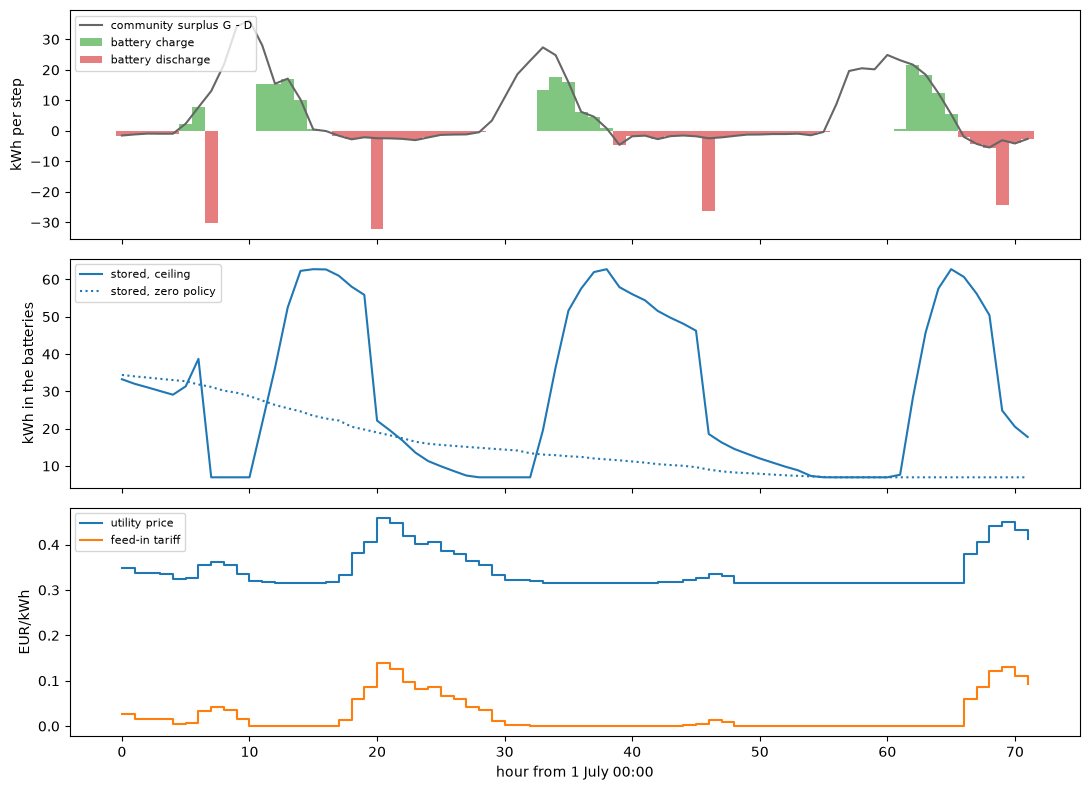

In [7]:
show = slice(0, 3 * market.n_steps)
p = plan_end.iloc[show]
charge = p.filter(regex="^charge").sum(axis=1)
discharge = p.filter(regex="^discharge").sum(axis=1)
stored = p.filter(regex="^stored").sum(axis=1)
hours = np.arange(len(p)) * H

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax1.plot(hours, net[show], color="0.4", label="community surplus G - D")
ax1.bar(hours, charge, width=H, color="tab:green", alpha=0.6, label="battery charge")
ax1.bar(hours, -discharge, width=H, color="tab:red", alpha=0.6, label="battery discharge")
ax1.set_ylabel("kWh per step"); ax1.legend(loc="upper left", fontsize=8)

passive_stored = []  # the zero policy's batteries, for comparison
for i in batteries:
    p_setup = next(q for q in scenario.participants if q.id == i)
    bat = Battery(p_setup.battery, H)
    agent = Participant(i, p_setup.bus, p_setup.owns, G[i].tolist(), D[i].tolist(), bat)
    passive_stored.append([(agent.settle(t, []), bat.energy_kwh)[1] for t in range(T)])
ax2.plot(hours, stored, color="tab:blue", label="stored, ceiling")
ax2.plot(hours, np.sum(passive_stored, axis=0)[show], color="tab:blue", ls=":", label="stored, zero policy")
ax2.set_ylabel("kWh in the batteries"); ax2.legend(loc="upper left", fontsize=8)

ax3.step(hours, util[show], where="post", label="utility price")
ax3.step(hours, fit[show], where="post", label="feed-in tariff")
ax3.set_ylabel("EUR/kWh"); ax3.set_xlabel("hour from 1 July 00:00"); ax3.legend(loc="upper left", fontsize=8)
plt.tight_layout()

## Where the trained runs sit

The value-to-ideal index (VTI) puts a run's team money between the non-P2P baseline (0)
and the ceiling with the end condition (1). The participation index (PI) asks whether
the gain reaches the participants: the share of them who end the 14 days with more
money than on their own (their non-P2P money, from `on_their_own` above). Next to it,
the worst and the median participant's gain over their own non-P2P money.

$$
\text{VTI} = \frac{\text{team money} - \text{non-P2P}}{\text{ceiling} - \text{non-P2P}},
\qquad
\text{PI} = \frac{1}{N} \sum_{i=1}^{N} \mathbb{1}\left[\text{money}_i > \text{non-P2P}_i\right]
$$

where $N = 13$ participants and $\text{money}_i$ is participant $i$'s `bill` over the 14
days. The VTI says how much of the reachable money the team made, the PI whether most
participants would want to take part.

Team money is the runs' `bill` summed over the participants and the 14 days: their
fees are in it, and surplus they spilled without a sell order earned nothing. Their
batteries' change over the horizon is listed next to it, since the ceiling with the end
condition may not end lower than it started. The zero policy lands below 0: in the
market its surplus is spilled for nothing, while the non-P2P baseline sells it at the
feed-in tariff.

In [8]:
if RUNS.exists():
    rows = []
    for f in sorted(RUNS.glob("*/heldout_agents.csv")):
        a = pd.read_csv(f)
        team = a.groupby("policy").agg(money=("bill", "sum"), fees=("fees", "sum"),
                                       spilled_kwh=("deferred_supply_kwh", "sum"),
                                       stored_change_kwh=("stored_change_kwh", "sum"))
        team["run"] = f.parent.name
        own = a.groupby(["policy", "agent"]).bill.sum().unstack("agent")
        gain = own - non_p2p_own[own.columns]
        team["PI"] = (gain > 0).mean(axis=1)
        team["worst_gain"] = gain.min(axis=1)
        team["median_gain"] = gain.median(axis=1)
        rows.append(team.reset_index())
    runs = pd.concat(rows)
    runs = pd.concat([runs[runs.policy == "trained"],
                      runs[runs.policy != "trained"].drop_duplicates("policy").assign(run="(baseline)")])
    runs["VTI"] = (runs.money - non_p2p) / (ceiling_end - non_p2p)
    cols = ["money", "VTI", "PI", "worst_gain", "median_gain",
            "fees", "spilled_kwh", "stored_change_kwh"]
    display(runs.set_index(["run", "policy"])[cols].sort_values("VTI", ascending=False).round(3))

,,money,VTI,PI,worst_gain,median_gain,fees,spilled_kwh,stored_change_kwh
run,policy,,,,,,,,
ppo_ctde_s0_bill_paper,trained,-5.508,0.399,0.923,-0.778,1.441,4.645,44.037,-17.476
ppo_ctde_s0_bill_pruned,trained,-23.894,0.317,0.846,-0.471,1.611,4.363,23.155,-18.379
ppo_dtde_s0_bill_pruned,trained,-24.374,0.314,0.769,-0.378,1.799,4.978,29.585,-20.000
ppo_dtde_s0_bill_paper,trained,-55.194,0.176,0.538,-0.648,0.279,4.332,18.167,-21.079
(baseline),net_position,-64.772,0.134,0.846,-0.839,2.510,8.735,0.000,-27.880
ppo_ctce_s0_bill_paper,trained,-75.438,0.086,0.385,-5.258,0.000,3.047,296.009,-23.061
ppo_ctce_s0_bill_pruned,trained,-100.658,-0.027,0.231,-3.113,-1.190,3.034,359.512,-27.880
ppo_dtde_s0_salazar_paper,trained,-185.699,-0.408,0.615,-60.414,3.520,8.677,877.589,22.201
(baseline),zero,-189.256,-0.424,0.000,-29.429,-6.841,0.000,2911.681,-27.880


## What the ceiling leaves out

- **Fees.** Trades with the DSO pay the eq. 8 fees in the runs; the ceiling pays none.
  The zone bonus is a negative fee, so in principle a run could pass the ceiling by it.
- **The grid.** No line or voltage limit and no losses: the ceiling is a money bound,
  not a feasible grid schedule.
- **Perfect foresight.** The planner knows every profile and tariff of all 14 days; the
  agents see one step at a time.
- **Spilled surplus.** The ceiling sells every surplus at the feed-in tariff; in the
  market a surplus earns it only through a sell order to the DSO.

So the gap between a run and the ceiling mixes what the agents could still learn with
what no step-by-step policy could reach. The ceiling is an upper bound for the VTI, not
a target to hit.